## Hierarchical Clustering

In [33]:
import numpy as np

np.random.seed(18)
n_products = 60

# Products with varying price and customer_rating, forming natural nested groups
price = np.concatenate([
    np.random.normal(15, 3, 20),    # budget items
    np.random.normal(50, 8, 20),    # mid-range
    np.random.normal(150, 20, 20)   # premium
])
rating = np.concatenate([
    np.random.normal(3.2, 0.4, 20),
    np.random.normal(4.0, 0.3, 20),
    np.random.normal(4.5, 0.2, 20)
])

X = np.column_stack([price, rating])

#### Tasks
- Apply scaling
- Plot dendrograms with all three linkage methods (single, complete, ward) and compare their shapes
- Decide K visually from the dendrogram
- Get the final labels with AgglomerativeClustering and draw a scatter plot
- Compare with K-Means on the same data and the same K. Are the results similar? Compare both using the Silhouette Score

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

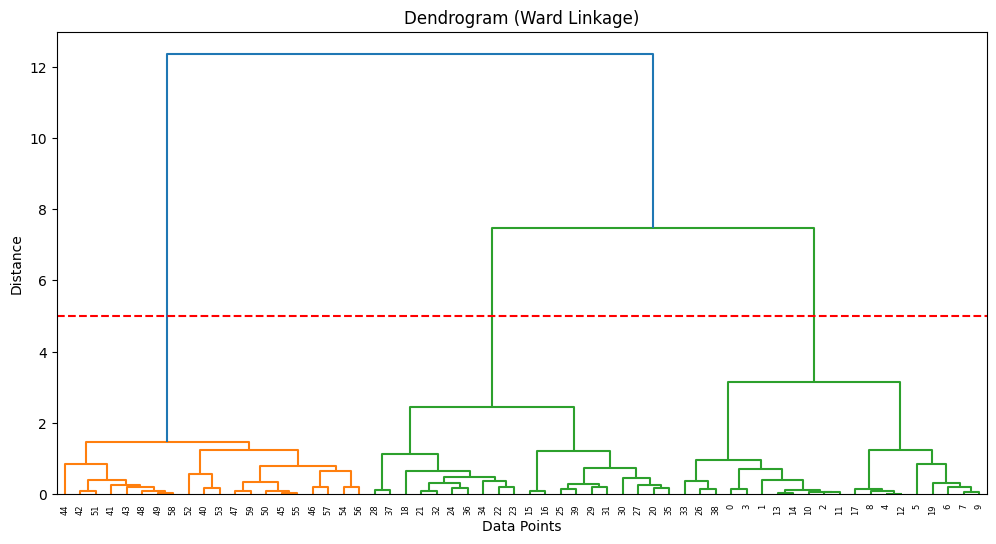

In [35]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

Z = linkage(X_scaled, method = 'ward')

plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.title("Dendrogram (Ward Linkage)")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.axhline(y=5, color='r', linestyle='--', label='Cut-off Threshold')
plt.show()

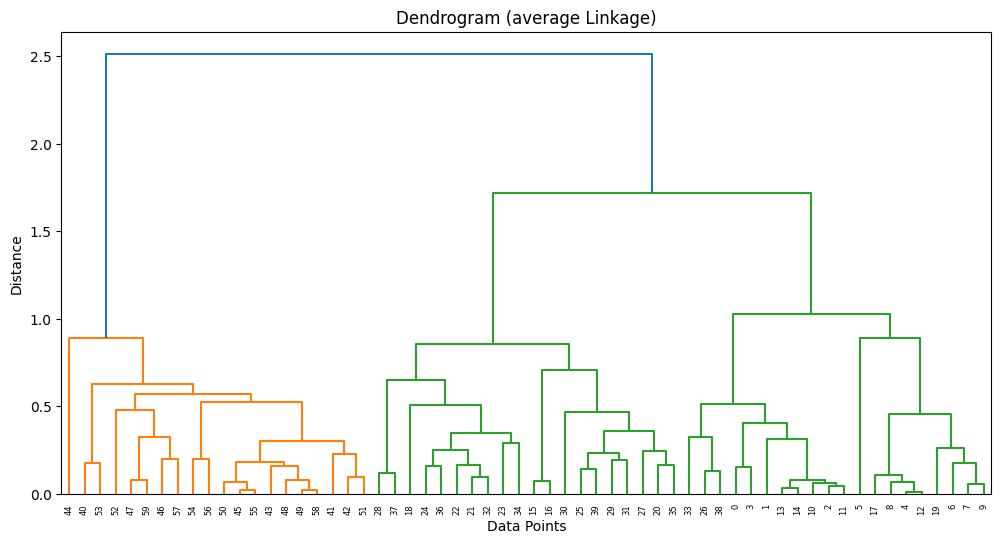

In [36]:
Z = linkage(X_scaled, method = 'average')

plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.title("Dendrogram (average Linkage)")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

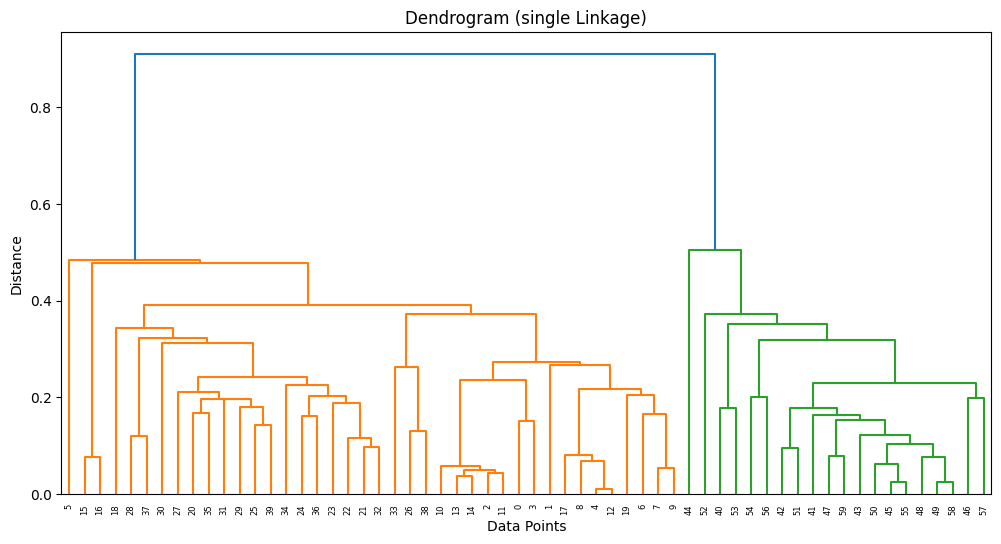

In [37]:
Z = linkage(X_scaled, method = 'single')

plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.title("Dendrogram (single Linkage)")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

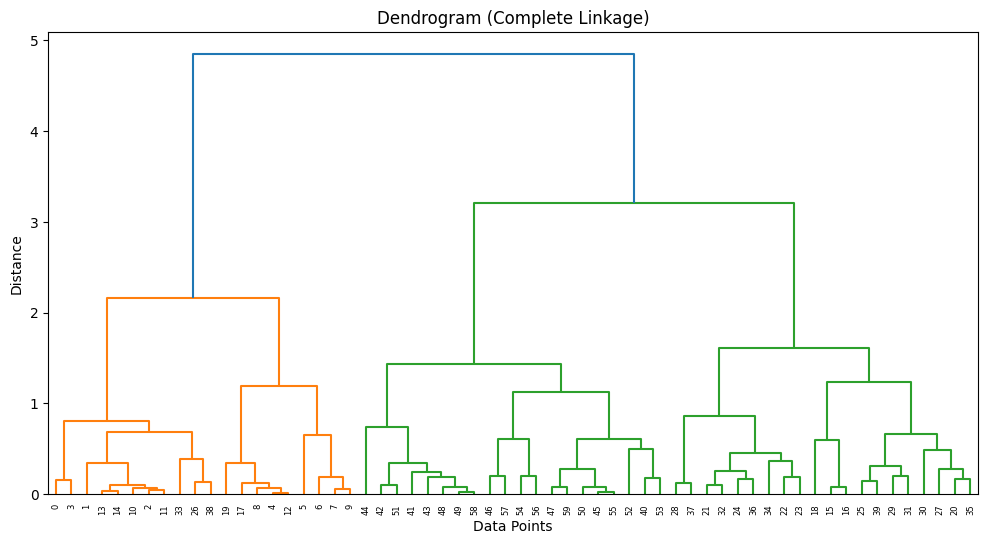

In [38]:
Z = linkage(X_scaled, method = 'complete')

plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.title("Dendrogram (Complete Linkage)")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

From the Dendogram I think the n_cluster would be 3

In [45]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

model = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels = model.fit_predict(X_scaled)
agglo_labels = model.fit_predict(X_scaled)
agglo_score = silhouette_score(X_scaled, agglo_labels)

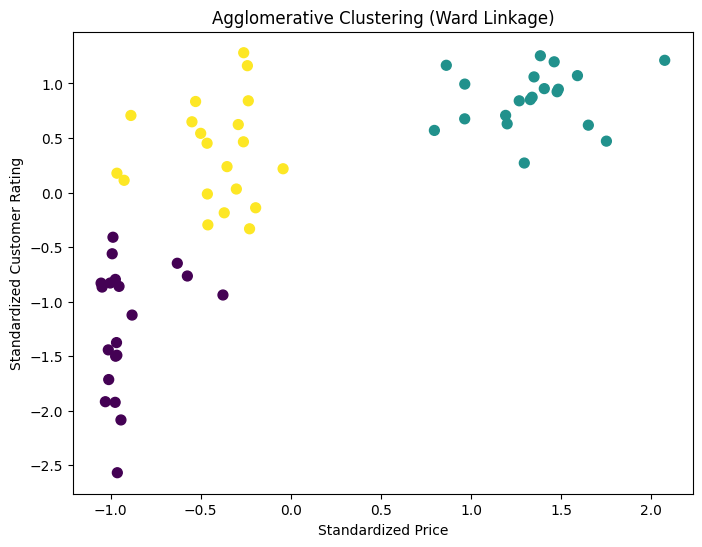

In [40]:
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap='viridis', s=50)
plt.title("Agglomerative Clustering (Ward Linkage)")
plt.xlabel("Standardized Price")
plt.ylabel("Standardized Customer Rating")
plt.show()

In [46]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_scaled)
kmeans_labels = kmeans.labels_
kmeans_score = silhouette_score(X_scaled, kmeans_labels)

In [47]:
print(f"Hierarchical (Ward) Silhouette: {agglo_score:.4f}")
print(f"K-Means Silhouette:             {kmeans_score:.4f}")
print(f"\nDo labels match? {np.array_equal(np.sort(np.unique(agglo_labels, return_counts=True)[1]), np.sort(np.unique(kmeans_labels, return_counts=True)[1]))}")
print(f"Agglo cluster sizes: {np.bincount(agglo_labels)}")
print(f"KMeans cluster sizes: {np.bincount(kmeans_labels)}")

Hierarchical (Ward) Silhouette: 0.6091
K-Means Silhouette:             0.6091

Do labels match? True
Agglo cluster sizes: [20 20 20]
KMeans cluster sizes: [20 20 20]
